# Can the context predict how EI's run ends, and does gating the UCB deviation by it beat the static schedule?

## Description

<!-- Written 2026-11-12 16:00 before the first run (pre-registration). Follows notebook 13 (option_policy, INCONCLUSIVE) and Tim's mandate of 2026-11-12 ("do both"). Issue #13. -->

**Question.** In notebook 13 the one-deviation policy beat EI only by as much as the static schedule "UCB(0.995) from t = 2" does. UCB helps a lot where EI ends badly and hurts where EI ends well. So:
1. **Probe.** Does the context at decision step t predict how EI's run will end (its terminal log10 regret)? Does the PFN's belief add to plain statistics of the data?
2. **Gate.** Does "deviate to UCB only if EI is predicted to end badly" beat the best static schedule?
3. **Ceiling.** What would such a gate gain if it *knew* EI's outcome on this task, luck-corrected? This bounds the idea whatever the predictor.

**What is already known** (scratch on notebook 13's pilot labels, run artifact `labels.pt` of `pilot_20261112-123724`; exploratory, the reason for this experiment, to be confirmed here on fresh tasks):
- EI's terminal regret is partly predictable: Spearman of a cross-fitted prediction with the outcome is 0.29–0.33 at t = 0, 0.45 at t = 2, 0.62 at t = 6, 0.71 at t = 14 with belief features; with data features only 0.22, 0.33, 0.60, 0.71. The current true regret (privileged) reaches 0.56 at t = 2 and 0.95 at t = 14.
- A gate on that prediction chose "always deviate" in every fold: gain over the static schedule 0.000.
- **Correction to notebook 13's post hoc.** There, giving the policy EI's own terminal regret as a feature gained +0.147 over static. That number is mostly mechanical: the same run's regret is half of the label. Gating by EI's outcome under the *other* candidate-set seed gives +0.156 [0.116, 0.201] at t = 2 against +0.131 for always deviating.
- By tercile of the other seed's EI outcome, "UCB for the rest" from t = 2 is worth −0.08, +0.02, +0.46: the hard third carries the whole gain, the loss on the easy third is small.

**Setup** (`tasks/ei_failure.py`, `analysis/ei_failure.py`; labels and context from `tasks/option_policy.py::collect`). d = 2, n_init = 4, T = 20, pfn_large, fp32, noise-free prior tasks, deterministic arms on seeded candidate sets (as notebooks 12–14).
- *Tasks.* 3000 fresh prior draws, split 4, task offset 50000.
- *Runs.* EI under seed 0 for the whole run. At every t ∈ {0, 2, …, 14}, from EI's data, under seeds 0 and 1: EI to T (the base), "UCB for 3 steps, then EI", "UCB for the rest".
- *Target* g: log10 terminal regret (ε = 1e-6) of the EI run under seed 0. *Luck replicate*: EI continued from step t under seed 1 (same data up to t, another candidate set afterwards).
- *Predictors* ĝ, cross-fitted over tasks (5 folds), from the feature sets `data` (18), `belief` (data + 45 belief features), `pfn` (belief + 32 PCA components of the PFN state): a ridge per decision step, and one MLP over all steps.
- *Gate.* Deviate at step j to option o iff score_j ≥ c. (j, o, c) are chosen on the training folds; for ĝ from predictions those tasks' models never saw. c = −∞ is the ungated static schedule and never deviating is allowed; both win ties.
  - deployable scores: ĝ of each feature set and learner. **Primary: `gate/belief/mlp`.**
  - privileged scores: `priv:other_seed` (EI's outcome from step j under seed 1; chosen and valued on seed-0 advantages: the luck-corrected ceiling); `priv:same_seed` (the target itself: mechanical, shown to make that visible); `priv:current_regret`.
- *Comparators.* EI (0); the best static (step, option) chosen on the training folds.

**What to look for.**
1. Probe: Spearman(ĝ, g) per decision step with bootstrap CIs; `belief` − `data` and `pfn` − `belief`, paired; against `priv:other_seed` (what any predictor could reach) and `priv:current_regret`.
2. Strata: the advantage of the UCB options by tercile of ĝ and of the other seed's outcome, per step.
3. Gates: gain over EI and over the static schedule, seed 0 (deployed) and seed 1 (executed on another candidate set).

**GO / NO-GO** (rule `analysis/option_policy.py::policy_verdict` on `gate/belief/mlp`, seed 0; worthwhile = 0.022 log10).
- **GO**: the gate beats EI (CI > 0) and beats the static schedule (CI > 0, ≥ 0.022). Then put ĝ into the option policy.
- **NO-GO**: the upper CI bound of the gate's gain over the static schedule is < 0.022. Expected from the exploration.
- **INCONCLUSIVE**: otherwise.
- Stated in advance for the ceiling: if `gate/priv:other_seed` gains less than 0.05 over the static schedule (upper CI bound), predicting EI's failure cannot make a single gated UCB deviation worthwhile, however good the predictor. The probe result stands on its own either way.

**Limits.**
- Noise-free P0, d = 2, T = 20. Only UCB options; one deviation.
- The luck replicate shares the data up to step t, so early steps are close to an independent run and late steps are not.
- The exploration above used notebook 13's tasks; the tasks here are fresh. Design choices (scores, grid, primary) were fixed before the first run.
- Labels carry GPU floating-point noise at the scale of ε (notebook 13).


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from anytime_acq.analysis import load_snapshot, show_header
from anytime_acq.analysis.option_policy import policy_verdict

SNAPSHOT = "results/ei_failure/pilot_20261113-075212"
snap = load_snapshot(SNAPSHOT)
show_header(snap)  # how it was run + configuration, generated from the snapshot

## How it was run

```bash
just sweep detached pilot experiment=ei_failure
```

|  |  |
|---|---|
| stage | pilot |
| sweep | `pilot_20261113-075212` |
| commit | `daaa02374c18` (tag `sweep/ei_failure/pilot_20261113-075212`) |
| backend / host | detached / ulysses |
| ran | 2026-11-13T07:52:14 → 2026-11-13T09:04:28 |
| members | 1: 1 done |
| compute | 1.2 h wall, 0.0 min GPU |

## Configuration

Experiment config (`configs/experiment/ei_failure.yaml`):

```yaml
# @package _global_
# Can the context predict how EI's run ends, and does gating the UCB deviation by it beat the static schedule?
# (issue #13). Pre-registration: notebooks/15_2026-11-12_ei_failure.ipynb.
defaults:
  - override /task: ei_failure

task:
  d: 2
```

**Varying:** nothing

**Replicates:** none

**Constant:**

```yaml
seed: 0
task:
  T_per_d: 10
  arms: '["ei", "ucb0.995"]'
  base: ei
  candidates.local_sigmas: '[0.01, 0.05, 0.2]'
  candidates.n_local: 64
  candidates.n_sobol: 1024
  chunk: 256
  d: 2
  device: cuda
  eps: 1.0e-06
  feature_sets: '["data", "belief", "pfn"]'
  fit.batch: 1024
  fit.dropout: 0.1
  fit.epochs: 150
  fit.lr: 0.002
  fit.n_ens: 2
  fit.patience: 15
  fit.weight_decay: 0.001
  fit.width: 128
  ks: '[3]'
  learners: '["ridge", "mlp"]'
  n_boot: 2000
  n_boot_corr: 300
  n_folds: 5
  n_init_per_d: 2
  n_inner: 4
  name: ei_failure
  pfn: pfn_large
  primary: gate/belief/mlp
  rest: true
  seeds: '[0, 1]'
  steps: '[0, 2, 4, 6, 8, 10, 12, 14]'
  task_chunk: 500
  task_draw.n_dense: 16384
  task_draw.n_refine: 16
  task_draw.refine_steps: 200
  tasks.n_tasks: 3000
  tasks.split: 4
  tasks.task_offset: 50000
  tf32: false
  worthwhile_log10: 0.022
  z_pca: 32
```

In [ ]:
runs = snap.runs
print("member status:", runs.status.value_counts().to_dict())
print("minutes:", {k: round(float(runs.iloc[0][k]) / 60, 1) for k in runs.columns if k.startswith("time/")})
summ, probe, pdiff, strata, gates, per, opts = (snap.table(k) for k in ("summary", "probe", "probe_diff", "strata", "gates", "per_task", "options"))
PRIMARY, WORTH = "gate/belief/mlp", 0.022
print("tasks:", len(per), "| EI terminal log10 regret: mean %.2f, sd %.2f" % (per.g0.mean(), per.g0.std()))
print("mean advantage over EI per step and option (seed 0 / seed 1):")
display(opts.pivot(index="option", columns="step", values="adv0").round(3)); display(opts.pivot(index="option", columns="step", values="adv1").round(3))

member status: {'DONE': 1}
minutes: {'time/collect_s': 70.9, 'time/evaluate_s': 1.3}
tasks: 3000 | EI terminal log10 regret: mean -4.57, sd 1.48
mean advantage over EI per step and option (seed 0 / seed 1):


step,0,2,4,6,8,10,12,14
option,,,,,,,,
ucb0.995_k3,0.024,0.059,0.093,0.109,0.119,0.117,0.102,0.080
ucb0.995_rest,0.110,0.112,0.109,0.089,0.082,0.058,0.036,0.011


step,0,2,4,6,8,10,12,14
option,,,,,,,,
ucb0.995_k3,0.021,0.025,0.077,0.102,0.118,0.116,0.084,0.081
ucb0.995_rest,0.107,0.070,0.094,0.082,0.069,0.052,0.004,0.012


## 1. Probe: is EI's terminal regret predictable from the context?

Spearman of the cross-fitted prediction with EI's terminal log10 regret, per decision step (priv: privileged references)


step,0,2,4,6,8,10,12,14
score,,,,,,,,
belief/mlp,0.289,0.461,0.568,0.631,0.676,0.708,0.721,0.740
belief/ridge,0.281,0.451,0.562,0.625,0.664,0.693,0.705,0.723
data/mlp,0.210,0.349,0.499,0.593,0.656,0.696,0.719,0.738
data/ridge,0.218,0.348,0.494,0.590,0.647,0.678,0.695,0.713
pfn/mlp,0.292,0.460,0.567,0.629,0.673,0.701,0.715,0.729
pfn/ridge,0.290,0.464,0.571,0.631,0.670,0.696,0.710,0.725
priv:current_regret,0.246,0.548,0.667,0.779,0.847,0.894,0.920,0.940
priv:other_seed,0.836,0.868,0.896,0.916,0.938,0.946,0.952,0.962


R2:


step,0,2,4,6,8,10,12,14
score,,,,,,,,
belief/mlp,0.076,0.176,0.278,0.346,0.408,0.450,0.459,0.488
belief/ridge,0.072,0.175,0.275,0.341,0.393,0.427,0.441,0.467
data/mlp,0.039,0.093,0.199,0.292,0.367,0.417,0.442,0.473
data/ridge,0.040,0.095,0.191,0.278,0.343,0.381,0.400,0.427
pfn/mlp,0.073,0.175,0.280,0.351,0.407,0.444,0.458,0.483
pfn/ridge,0.075,0.183,0.283,0.356,0.403,0.438,0.454,0.478


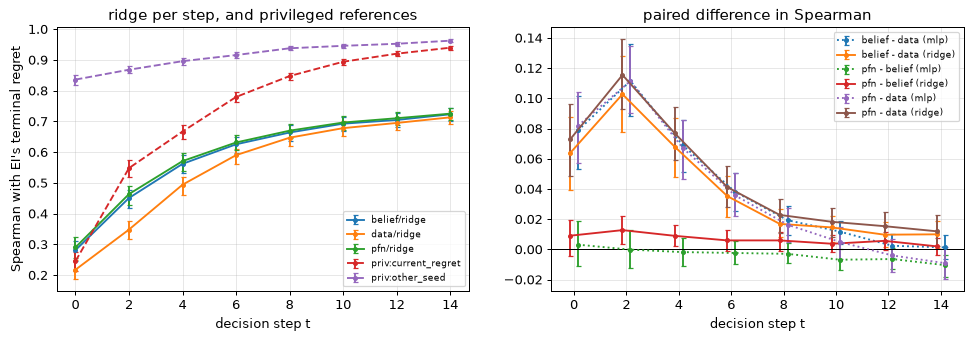

step                                        0                        2   \
a      b      learner                                                     
belief data   mlp      +0.079 [+0.053, +0.102]  +0.112 [+0.089, +0.136]   
              ridge    +0.064 [+0.039, +0.088]  +0.103 [+0.078, +0.128]   
pfn    belief mlp      +0.003 [-0.011, +0.019]  -0.000 [-0.012, +0.013]   
              ridge    +0.009 [-0.004, +0.020]  +0.013 [+0.004, +0.022]   
       data   mlp      +0.082 [+0.057, +0.104]  +0.111 [+0.090, +0.135]   
              ridge    +0.073 [+0.049, +0.096]  +0.115 [+0.093, +0.139]   

step                                        4                        6   \
a      b      learner                                                     
belief data   mlp      +0.069 [+0.051, +0.086]  +0.038 [+0.025, +0.050]   
              ridge    +0.068 [+0.048, +0.087]  +0.035 [+0.022, +0.048]   
pfn    belief mlp      -0.002 [-0.011, +0.007]  -0.002 [-0.010, +0.005]   
              ridge    +0.009 [+0.002, +0.016]  +0.006 [-0.001, +0.013]   
       data   mlp      +0.067 [+0.047, +0.086]  +0.036 [+0.022, +0.050]   
              ridge    +0.077 [+0.059, +0.094]  +0.041 [+0.028, +0.055]   

step                                        8                        10  \
a      b      learner                                                     
belief data   mlp      +0.019 [+0.010, +0.029]  +0.012 [+0.003, +0.019]   
              ridge    +0.017 [+0.008, +0.027]  +0.015 [+0.005, +0.022]   
pfn    belief mlp      -0.003 [-0.009, +0.004]  -0.007 [-0.014, +0.001]   
              ridge    +0.006 [-0.001, +0.012]  +0.004 [-0.002, +0.010]   
       data   mlp      +0.016 [+0.005, +0.027]  +0.005 [-0.006, +0.015]   
              ridge    +0.023 [+0.011, +0.033]  +0.018 [+0.008, +0.027]   

step                                        12                       14  
a      b      learner                                                    
belief data   mlp      +0.002 [-0.006, +0.010]  +0.001 [-0.007, +0.010]  
              ridge    +0.010 [+0.002, +0.018]  +0.010 [+0.001, +0.019]  
pfn    belief mlp      -0.006 [-0.013, +0.001]  -0.010 [-0.018, -0.003]  
              ridge    +0.006 [-0.000, +0.011]  +0.002 [-0.004, +0.007]  
       data   mlp      -0.004 [-0.015, +0.007]  -0.009 [-0.019, +0.002]  
              ridge    +0.015 [+0.006, +0.025]  +0.012 [+0.002, +0.023]

In [ ]:
print("Spearman of the cross-fitted prediction with EI's terminal log10 regret, per decision step (priv: privileged references)")
display(probe.pivot(index="score", columns="step", values="spearman").round(3))
print("R2:"); display(probe[~probe.score.str.startswith("priv")].pivot(index="score", columns="step", values="r2").round(3))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), dpi=90)
for sc, g in probe.groupby("score"):
    if sc.endswith("/mlp"): continue
    ax[0].errorbar(g.step, g.spearman, yerr=[g.spearman - g.lo, g.hi - g.spearman], marker="o", ms=3, capsize=2, ls="--" if sc.startswith("priv") else "-", label=sc)
ax[0].set_xlabel("decision step t"); ax[0].set_ylabel("Spearman with EI's terminal regret"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3); ax[0].set_title("ridge per step, and privileged references")
for (a, b, l), g in pdiff.groupby(["a", "b", "learner"]):
    ax[1].errorbar(g.step + {"ridge": -.15, "mlp": .15}[l], g["diff"], yerr=[g["diff"] - g.lo, g.hi - g["diff"]], marker="o", ms=3, capsize=2, ls="-" if l == "ridge" else ":", label=f"{a} - {b} ({l})")
ax[1].axhline(0, color="k", lw=.8); ax[1].set_xlabel("decision step t"); ax[1].set_title("paired difference in Spearman"); ax[1].legend(fontsize=7); ax[1].grid(alpha=.3)
plt.show()
display(pdiff.assign(ci=[f"{d:+.3f} [{lo:+.3f}, {hi:+.3f}]" for d, lo, hi in zip(pdiff["diff"], pdiff.lo, pdiff.hi)]).pivot(index=["a", "b", "learner"], columns="step", values="ci"))

## 2. Strata: where does UCB pay? Advantage by tercile of the predicted / the other seed's / the same seed's EI outcome

In [ ]:
for sc, g in strata[strata.option.str.endswith("_rest")].groupby("score"):
    print(sc, "- advantage of 'UCB for the rest' over EI (seed 0); tercile 0 = EI predicted / known to end best")
    display(g.pivot(index="tercile", columns="step", values="adv0").round(3))
g = strata[(strata.option.str.endswith("_k3")) & (strata.score == "priv:other_seed")]
print("priv:other_seed - 'UCB for 3 steps'"); display(g.pivot(index="tercile", columns="step", values="adv0").round(3))

belief/mlp - advantage of 'UCB for the rest' over EI (seed 0); tercile 0 = EI predicted / known to end best


step,0,2,4,6,8,10,12,14
tercile,,,,,,,,
0,0.140,0.155,0.157,0.134,0.087,0.050,0.055,0.029
1,0.139,0.183,0.204,0.224,0.241,0.206,0.113,0.077
2,0.052,-0.002,-0.033,-0.091,-0.081,-0.083,-0.061,-0.073


priv:other_seed - advantage of 'UCB for the rest' over EI (seed 0); tercile 0 = EI predicted / known to end best


step,0,2,4,6,8,10,12,14
tercile,,,,,,,,
0,-0.023,-0.053,-0.085,-0.055,-0.047,-0.056,-0.044,-0.025
1,0.061,0.012,-0.001,-0.061,-0.054,-0.045,-0.061,-0.069
2,0.292,0.376,0.413,0.383,0.349,0.274,0.213,0.127


priv:same_seed - advantage of 'UCB for the rest' over EI (seed 0); tercile 0 = EI predicted / known to end best


step,0,2,4,6,8,10,12,14
tercile,,,,,,,,
0,-0.185,-0.184,-0.156,-0.130,-0.105,-0.087,-0.068,-0.054
1,-0.076,-0.070,-0.059,-0.075,-0.071,-0.071,-0.079,-0.077
2,0.592,0.589,0.542,0.472,0.423,0.332,0.254,0.163


priv:other_seed - 'UCB for 3 steps'


step,0,2,4,6,8,10,12,14
tercile,,,,,,,,
0,-0.080,-0.063,-0.038,-0.028,-0.019,-0.016,-0.015,-0.013
1,-0.019,-0.027,0.037,0.056,0.043,0.048,0.043,0.035
2,0.172,0.268,0.282,0.299,0.332,0.319,0.278,0.220


## 3. Gates: gain over EI and over the static schedule

In [ ]:
def show(seed):
    s = summ[summ.seed == seed]
    t = s.assign(ci=[f"{m:+.3f} [{lo:+.3f}, {hi:+.3f}]" for m, lo, hi in zip(s["mean"], s.lo, s.hi)])
    out = t.pivot(index="variant", columns="contrast", values="ci")
    out["deviates"] = s.groupby("variant").deviates.first().round(2)
    return out
print("log10 terminal regret, positive = better; held-out tasks, 95% bootstrap CI")
print("seed 0 (deployed):"); display(show(0))
print("seed 1 (the decision executed on the other candidate set; not meaningful for priv:other_seed, whose score is that run):"); display(show(1))
print("gates chosen per fold (step -1 = never deviate; c = -inf: the ungated static schedule):")
display(gates.pivot(index="variant", columns="fold", values=["step", "option", "c"]).round(2))

log10 terminal regret, positive = better; held-out tasks, 95% bootstrap CI
seed 0 (deployed):


contrast,vs_base,vs_static,deviates
variant,,,
gate/belief/mlp,"+0.109 [+0.084, +0.133]","+0.000 [+0.000, +0.000]",1.00
gate/belief/ridge,"+0.109 [+0.084, +0.133]","+0.000 [+0.000, +0.000]",1.00
gate/data/mlp,"+0.109 [+0.084, +0.133]","+0.000 [+0.000, +0.000]",1.00
gate/data/ridge,"+0.109 [+0.084, +0.133]","+0.000 [+0.000, +0.000]",1.00
gate/pfn/mlp,"+0.108 [+0.084, +0.132]","-0.001 [-0.003, +0.000]",0.99
gate/pfn/ridge,"+0.109 [+0.084, +0.133]","+0.000 [+0.000, +0.000]",1.00
gate/priv:current_regret,"+0.109 [+0.084, +0.133]","-0.000 [-0.002, +0.001]",0.69
gate/priv:other_seed,"+0.147 [+0.117, +0.177]","+0.038 [+0.008, +0.067]",0.45
gate/priv:same_seed,"+0.207 [+0.177, +0.238]","+0.098 [+0.068, +0.129]",0.44


seed 1 (the decision executed on the other candidate set; not meaningful for priv:other_seed, whose score is that run):


contrast,vs_base,vs_static,deviates
variant,,,
gate/belief/mlp,"+0.113 [+0.088, +0.137]","+0.000 [+0.000, +0.000]",1.00
gate/belief/ridge,"+0.113 [+0.088, +0.137]","+0.000 [+0.000, +0.000]",1.00
gate/data/mlp,"+0.113 [+0.088, +0.137]","+0.000 [+0.000, +0.000]",1.00
gate/data/ridge,"+0.113 [+0.088, +0.137]","+0.000 [+0.000, +0.000]",1.00
gate/pfn/mlp,"+0.112 [+0.087, +0.136]","-0.001 [-0.004, +0.000]",0.99
gate/pfn/ridge,"+0.113 [+0.088, +0.137]","+0.000 [+0.000, +0.000]",1.00
gate/priv:current_regret,"+0.113 [+0.088, +0.137]","+0.000 [-0.001, +0.001]",0.69
gate/priv:other_seed,"+0.202 [+0.170, +0.232]","+0.089 [+0.057, +0.122]",0.45
gate/priv:same_seed,"+0.101 [+0.067, +0.133]","-0.012 [-0.048, +0.023]",0.44


gates chosen per fold (step -1 = never deviate; c = -inf: the ungated static schedule):


step                      option                 \
fold                        0  1  2  3   4              0              1   
variant                                                                    
gate/belief/mlp             8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/belief/ridge           8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/data/mlp               8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/data/ridge             8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/pfn/mlp                8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/pfn/ridge              8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/priv:current_regret    8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   
gate/priv:other_seed        4  4  4  4   4  ucb0.995_rest  ucb0.995_rest   
gate/priv:same_seed         0  0  0  0   2  ucb0.995_rest  ucb0.995_rest   
static                      8  8  8  8  10    ucb0.995_k3    ucb0.995_k3   

                                                                       \
fold                                  2              3              4   
variant                                                                 
gate/belief/mlp             ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/belief/ridge           ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/data/mlp               ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/data/ridge             ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/pfn/mlp                ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/pfn/ridge              ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/priv:current_regret    ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   
gate/priv:other_seed      ucb0.995_rest  ucb0.995_rest  ucb0.995_rest   
gate/priv:same_seed       ucb0.995_rest  ucb0.995_rest  ucb0.995_rest   
static                      ucb0.995_k3    ucb0.995_k3    ucb0.995_k3   

                                 c                                          
fold                             0         1         2         3         4  
variant                                                                     
gate/belief/mlp               -inf      -inf      -inf      -inf      -inf  
gate/belief/ridge             -inf      -inf      -inf      -inf      -inf  
gate/data/mlp                 -inf      -inf      -inf      -inf      -inf  
gate/data/ridge               -inf      -inf      -inf      -inf      -inf  
gate/pfn/mlp                  -inf -5.944998      -inf      -inf      -inf  
gate/pfn/ridge                -inf      -inf      -inf      -inf      -inf  
gate/priv:current_regret -5.490553 -5.709148 -5.458105  -5.46921 -5.096615  
gate/priv:other_seed     -4.806586 -4.807376 -4.883519 -4.824255 -4.895334  
gate/priv:same_seed      -5.099379 -5.096354  -4.49848 -4.491987 -4.515694  
static                        -inf      -inf      -inf      -inf      -inf

## Observations (pilot, snapshot `results/ei_failure/pilot_20261113-075212`)

Written after the run. 3000 fresh tasks, 5 folds, log10 terminal regret, ε = 1e-6, seed 0 unless noted. Collection took 71 min, the evaluation 1.3 min.

- **Probe: EI's terminal regret is partly predictable from the context, and the belief helps early.**
  - Spearman of the cross-fitted prediction with the outcome (`belief/mlp`): 0.29 at t = 0, 0.46 at t = 2, 0.63 at t = 6, 0.74 at t = 14.
  - Belief over data features: +0.079 [0.053, 0.102] at t = 0, +0.112 [0.089, 0.136] at t = 2, +0.038 [0.025, 0.050] at t = 6, ≈ 0 from t = 12 (MLP; ridge the same). The PFN reading adds to D-only statistics while the data are few.
  - The PFN state on top of the belief features: within ±0.01 at every step.
  - References: the same policy on the other candidate set correlates 0.84–0.96 with the outcome; the current true regret 0.25 at t = 0, 0.55 at t = 2, 0.94 at t = 14.
- **Gate: NO-GO.** The gate on the prediction chose the ungated static schedule in every fold, for every feature set and learner: gain over static +0.000. The gate on the current true regret (privileged): −0.000 [−0.002, 0.001].
  - The static schedule here is "UCB for 3 steps at t = 8 (or 10)", +0.109 [0.084, 0.133] over EI; "UCB for the rest" from t = 0–4 is at +0.11 as well.
- **Ceiling: small, but not below the 0.05 stated in advance.** Gating by EI's outcome on the other candidate set: +0.038 [0.008, 0.067] over static (it deviates in 45% of tasks, to "UCB for the rest" at t = 4).
- **The same-seed outcome is mechanical, as suspected:** +0.098 [0.068, 0.129] over static on seed 0, but −0.012 [−0.048, 0.023] when the same decisions are scored on seed 1.
- **Why the prediction does not gate (strata, post hoc reading):** the predictable part of EI's outcome is not the part that matters for UCB.
  - By tercile of the *other seed's* EI outcome, "UCB for the rest" from t = 4 is worth −0.09, −0.00, +0.41.
  - By tercile of the *predicted* outcome it is +0.16, +0.20, −0.03: where EI is predicted to end worst, UCB does not help.
  - So the context predicts how hard the task is for every arm. That cancels in the advantage. Which tasks EI in particular fails on is what the context does not show.


## Verdict

The GO / NO-GO criterion from the description, evaluated, in one line. Record it with `just decide`.

**NO-GO** (pilot): the gate on the predicted EI outcome equals the static schedule (+0.000); the luck-corrected privileged ceiling is +0.038 [0.008, 0.067].


In [ ]:
print("pre-registered rule on", PRIMARY, "seed 0:", policy_verdict(summ, PRIMARY, WORTH))
c = summ[(summ.variant == "gate/priv:other_seed") & (summ.seed == 0) & (summ.contrast == "vs_static")].iloc[0]
print(f"ceiling (luck-corrected privileged gate) over static: {c['mean']:+.3f} [{c.lo:+.3f}, {c.hi:+.3f}]; below 0.05: {c.hi < 0.05}")

pre-registered rule on gate/belief/mlp seed 0: NO-GO
ceiling (luck-corrected privileged gate) over static: +0.038 [+0.008, +0.067]; below 0.05: False
